### Base simulation:
- Activate only one source dipole $\rightarrow$ $x_{1,t} = A \text{sin}(2\pi t)$
- Forward using the tutorial ```30_forward.ipynb```
- Produce output with the model: $Y = LX +E$, where $E_{n,t} \sim \text{N}(0, \beta^{-1}I)$
- Check metrics of the result:
    - $||X-\hat{X}||_{F}$
    - $\text{F}_{1}$-score on activation

1. Obtaining the matrix L (A of the model) from mne

In [1]:
import mne
import numpy as np
import pyvista
pyvista.set_jupyter_backend(None)

In [2]:
montage = mne.channels.make_standard_montage("colin27_1020")
chs = [c for c in montage.ch_names if c not in ["T3", "T4", "T5", "T6"]]
info = mne.create_info(chs, sfreq=250.0, ch_types="eeg")
info.set_montage(montage)

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fpz, Fp2, AF9, AF7, AF5, AF3, AF1, AFz, AF2, AF4, AF6, AF8, ...
 chs: 90 EEG
 custom_ref_applied: False
 dig: 93 items (3 Cardinal, 90 EEG)
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: unspecified
 nchan: 90
 projs: []
 sfreq: 250.0 Hz
>

In [3]:
sphere = mne.make_sphere_model(r0="auto", head_radius="auto", info=info)
src = mne.setup_volume_source_space(
    sphere=sphere, pos=15.0, exclude=30.0, add_interpolator=False
)

Fitted sphere radius:         99.1 mm
Origin head coordinates:      -1.0 13.8 38.3 mm
Origin device coordinates:    -1.0 13.8 38.3 mm

Equiv. model fitting -> RV = 0.00347616 %%
mu1 = 0.944836    lambda1 = 0.136856
mu2 = 0.66776    lambda2 = 0.683695
mu3 = -0.291317    lambda3 = -0.0101806
Set up EEG sphere model with scalp radius    99.1 mm

Sphere                : origin at (-1.0 13.8 38.3) mm
              radius  : 89.2 mm
grid                  : 15.0 mm
mindist               : 5.0 mm
Exclude               : 30.0 mm

Setting up the sphere...
Surface CM = (  -1.0   13.8   38.3) mm
Surface fits inside a sphere with radius   89.2 mm
Surface extent:
    x =  -90.1 ...   88.2 mm
    y =  -75.3 ...  103.0 mm
    z =  -50.9 ...  127.4 mm
Grid extent:
    x = -105.0 ...   90.0 mm
    y =  -90.0 ...  105.0 mm
    z =  -60.0 ...  135.0 mm
2744 sources before omitting any.
840 sources after omitting infeasible sources not within 30.0 - 89.2 mm.
Source spaces are in MRI coordinates.
Checking t

In [4]:
fwd = mne.make_forward_solution(
    info, trans=None, src=src, bem=sphere, meg=False, eeg=True, mindist=5.0
)
L = fwd["sol"]["data"]

Source space          : <SourceSpaces: [<discrete, n_used=710>] MRI (surface RAS) coords, ~698 KiB>
MRI -> head transform : identity
Measurement data      : instance of Info
Sphere model      : origin at [-0.0009528   0.01381019  0.03826742] mm
Standard field computations
Do computations in head coordinates
Free source orientations

Read 1 source spaces a total of 710 active source locations

Coordinate transformation: MRI (surface RAS) -> head
    1.000000 0.000000 0.000000       0.00 mm
    0.000000 1.000000 0.000000       0.00 mm
    0.000000 0.000000 1.000000       0.00 mm
    0.000000 0.000000 0.000000       1.00

Read  90 EEG channels from info
Head coordinate coil definitions created.
Source spaces are now in head coordinates.

Using the sphere model.

Source spaces are in head coordinates.
Checking that the sources are inside the surface and at least    5.0 mm away (will take a few...)
Using the equivalent source approach in the homogeneous sphere for EEG
Computing EEG at 710 s

In [5]:
L.shape[1]

2130

2. Set up the small simulation with only $x_1$ activated.

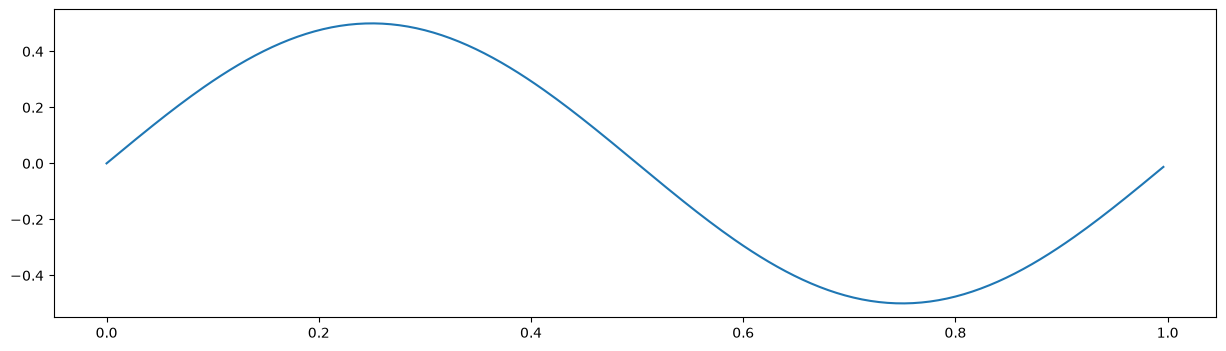

In [6]:
t = np.linspace(0, 1, int(info["sfreq"]), endpoint=False)
A = 0.5

# Signal of the first dipole
x_1 = A * np.sin(2 * np.pi * t)
X = np.zeros((L.shape[1], int(info["sfreq"])))
X[0] = x_1

# Plot the signal
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 4))
plt.plot(t, x_1)

3. "Forward" of the signal.

In [7]:
beta = 4
e = np.random.normal(0, 1/beta, size=(L.shape[0], int(info["sfreq"])))

Y = L @ X + e

EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


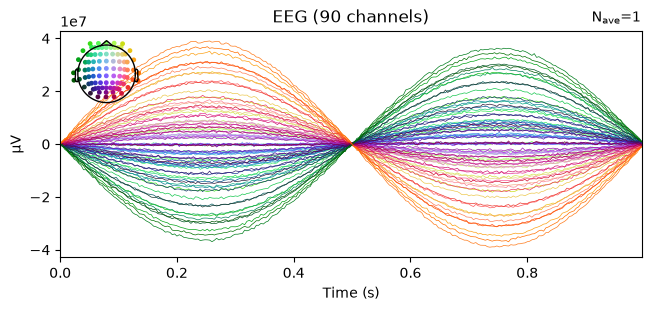

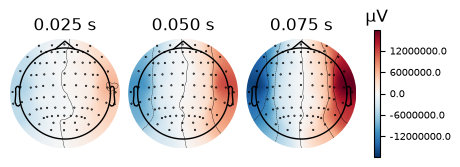

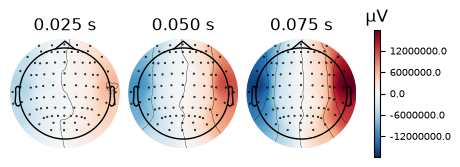

In [8]:
evoked = mne.EvokedArray(Y, info, tmin=0.0)
evoked.set_eeg_reference("average", projection=False)   # referencia promedio
evoked.plot(spatial_colors=True)
evoked.plot_topomap(times=[0.025, 0.05, 0.075])

4. Calculation and plot of the inverse solution using champagne algorithm.

In [9]:
from scipy.linalg import cho_factor, cho_solve


def champagne(y, leadfield, beta, phi_init, max_iter=1000, tol=1e-6):
    """
    Champagne algorithm for source localization.

    Parameters
    ----------
    y : array-like, shape (n_sensors, n_timepoints)
        The sensor measurements over time.
    leadfield : array-like, shape (n_sensors, n_dipoles)
        The leadfield matrix mapping dipoles to sensors.
    beta : float
        Regularization parameter.
    phi_init : array-like, shape (n_dipoles,)
        Initial values for the source variances (diagonal of phi).
    max_iter : int, optional
        Maximum number of iterations for the algorithm (default is 1000).
    tol : float, optional
        Tolerance for convergence (default is 1e-6).

    Returns
    -------
    phi : array-like, shape (n_dipoles,)
        Estimated source variances after convergence.
    """

    phi = phi_init.copy()

    leadfield_mult = leadfield.T @ leadfield
    leadfield_y = leadfield.T @ y
    n_timepoints = y.shape[1]

    # Iterative update of source variances
    for _ in range(max_iter):
        # Save the current phi for convergence check
        phi_prev = phi.copy()

        # Compute Gamma = diag(phi) + beta * L^T L (symmetric positive definite)
        Gamma = beta * leadfield_mult
        Gamma[np.diag_indices_from(Gamma)] += phi

        # One Cholesky factorization, reused for both solves
        c_and_lower = cho_factor(Gamma, check_finite=False)

        # Compute x_hat
        x_hat = beta * cho_solve(c_and_lower, leadfield_y, check_finite=False)

        # Update phi (only the diagonal is needed)
        full_matrix = beta * cho_solve(c_and_lower, leadfield_mult, check_finite=False)
        num = np.diag(full_matrix)
        phi = num / ((np.sum(x_hat ** 2, axis=1) + 1e-10) / n_timepoints)

        # Check for convergence
        if np.linalg.norm(phi - phi_prev) < tol:
            break

    return phi

In [ ]:
phi_init = np.ones(L.shape[1]) * 1e-3  # Initial source variances
phi_estimated = champagne(Y, L, beta=4, phi_init=phi_init, max_iter=1000, tol=1e-6)

ValueError: diag requires an array of at least two dimensions

In [13]:
phi_estimated

array([7.99960120e+00, 6.24745037e+08, 3.32850723e+08, ...,
       1.01985963e+09, 1.19772349e+09, 1.20252141e+09], shape=(2130,))

In [14]:
# Variance of x_1
var_x1_estimated = 1/phi_estimated[0]
var_x1_theoretical = A**2 / 2
var_x1_experimental = np.var(x_1)
print("Estimated variance of x_1:", var_x1_estimated)
print("Theoretical variance of x_1:", var_x1_theoretical)
print("Experimental variance of x_1:", var_x1_experimental)

Estimated variance of x_1: 0.12500623148569742
Theoretical variance of x_1: 0.125
Experimental variance of x_1: 0.12499999999999999


In [ ]:
def f1_score(X, phi_hat, threshold_source_variance=1e5, threshold_true_variance=1e-5):
    """
    Compute the F1 score for the estimated source variances.
    
    Parameters
    ----------
    X : array-like, shape (n_dipoles, n_timepoints)
        The true source signals over time.
    phi_hat : array-like, shape (n_dipoles, n_dipoles)
        The estimated source variances after convergence.
    Returns
    -------s
    f1 : float
        The F1 score for the estimated source variances.
    """
    # Identify activated dipoles based on the estimated source variances
    activated_estimated = np.where(phi_hat < threshold_source_variance)[0]
    
    # Identify activated dipoles based on the true source signals
    activated_true = np.where([np.var(X[i]) > threshold_true_variance for i in range(X.shape[0])])[0]
    
    # Compute true positives, false positives, and false negatives
    tp = len(set(activated_estimated) & set(activated_true))
    fp = len(set(activated_estimated) - set(activated_true))
    fn = len(set(activated_true) - set(activated_estimated))
    
    # Compute precision and recall
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    
    # Compute F1 score
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0
    
    return f1

In [ ]:
f1 = f1_score(X, phi_estimated)
print("F1 score for the estimated source variances:", f1)

F1 score for the estimated source variances: 1.0


Problems: (different seeds):

    - Sparsity (number active sources/dimensionality)

    - Number electrodes/number of sources -> ration N/D
    
    - SNR

p(x) = (1-pi)delta/N(o,eps) + piN(o,sigma) --> HMC, Langevin, SMC

P(Y,X)=P(Y|X)P(X)=prod_T N(y_t|Ax_t,E)prod_T prod_D p(X) X(t-student low degree, spike and slab, horse)

amortized inference (neural posterior est) -> X~P(X) --> Y = AX +E -> ^X = f(Y) nn